# Annotate abundance changes with ClinVar labels

In [24]:
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../..")
from analyses_plot_utils import *
warnings.filterwarnings('ignore')

# Set style
sns.set_style(style='white')
# sns.set_palette("husl")

## 0. Load data

In [26]:
dualipa_outputs = "../3_outputs"
metadata_outputs = "../../../1_allele_collection/1_inputs"
integrative_inputs = "../../../3_integrated_assay_analyses/1_inputs/dual_ipa"
# priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]

# merge scores with metadata
scores = pl.read_csv(f"{dualipa_outputs}/annotated_perturbation_scores.csv", separator=",", infer_schema_length=1000000)
scores = scores.with_columns(
    pl.when(pl.col("inheritance_pattern").is_null())
    .then(pl.lit("unknown"))
    .otherwise(pl.col("inheritance_pattern"))
    .alias("inheritance_pattern"),
    pl.col("clinvar_clnsig_clean").replace(
        {"Pathogenic": "PLP", "Benign": "BLB"}
    ).alias("clinvar_clnsig_clean")
)
hue_order = [c for c in clinvar_order_dict["original"] if "patho" not in c.lower() and "benign" not in c.lower()]
clinvar_palette_old = {k: v for k, v in palette_dict["clinvar_clnsig_clean"].items() if "patho" not in k.lower() and "benign" not in k.lower()} ## _pp_strict

## 1. Data Summary

### 1.1 DUAL-IPA profiled gene and variant info

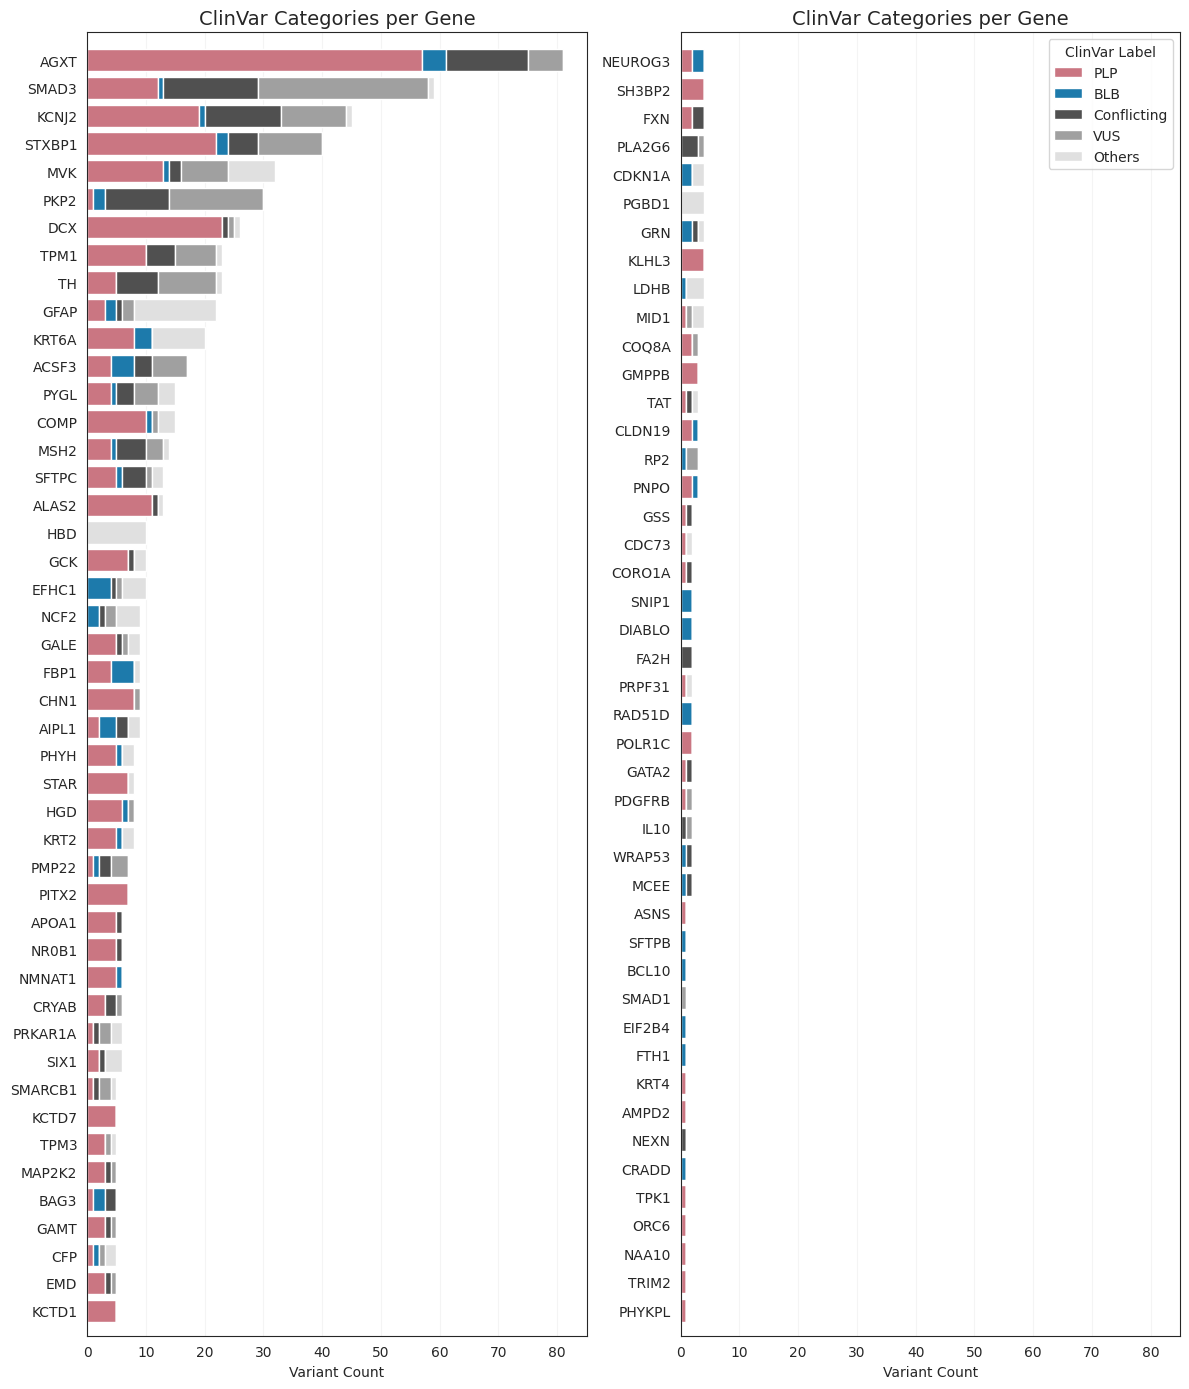

In [27]:
# 2. Count per (gene, category)
top_num = int(np.ceil(scores.unique("symbol").shape[0] / 2))
counts = (
    scores.to_pandas().groupby(["symbol", "clinvar_clnsig_clean"]) ## _pp_strict
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])
# category_order = sorted(pivot_top["clinvar_clnsig_clean"].unique())

# 4. Ensure category order
for cat in hue_order:
    if cat not in pivot_top.columns:
        pivot_top[cat] = 0
pivot_top = pivot_top[hue_order]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in clinvar_palette_old.items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 85)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
axes[0].set_title(f"ClinVar Categories per Gene", fontsize=14) ##  (Top {top_num} with Most Variants)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")
# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
for cat in hue_order:
    if cat not in pivot_bot.columns:
        pivot_bot[cat] = 0
pivot_bot = pivot_bot[hue_order]

bottom = None
for cat, color in clinvar_palette_old.items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 85)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
axes[1].set_title(f"ClinVar Categories per Gene", fontsize=14) ## ({top_num} After)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.tight_layout()
plt.show()

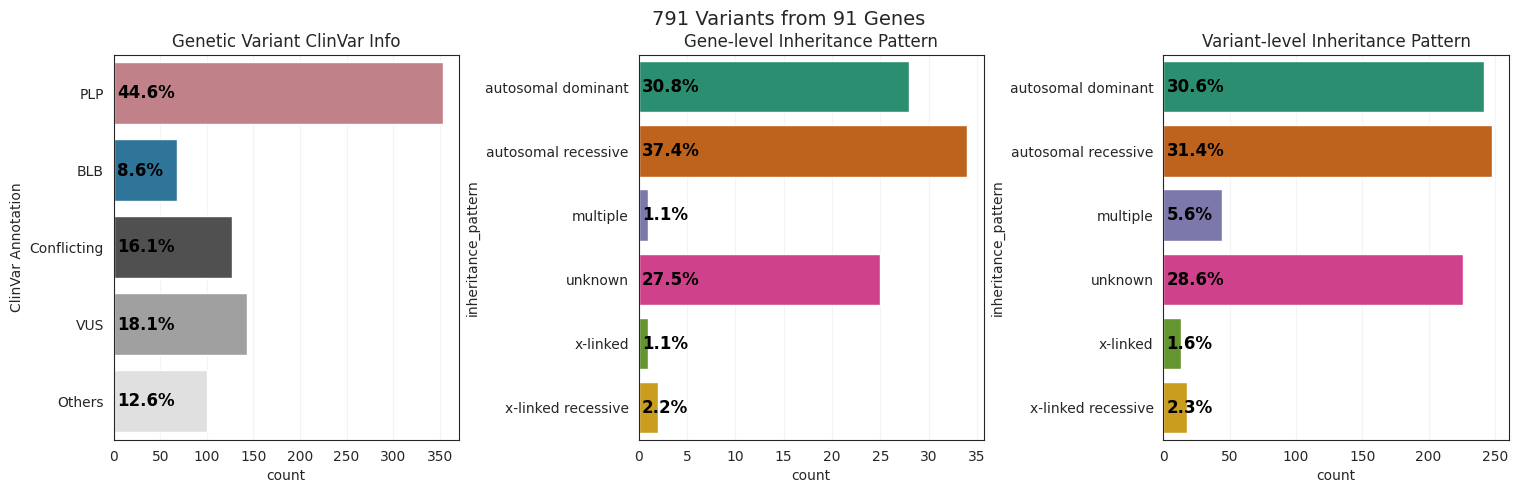

In [29]:
df = scores.to_pandas()

fig, axes = plt.subplots(1,3,figsize=(18,5))
plot_cat_count_perc(
    scores.with_columns(
        pl.col("clinvar_clnsig_clean") #_pp_strict
        .cast(pl.Enum([cat for cat in hue_order]))
    ).sort("clinvar_clnsig_clean"),
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"],
)
axes[0].set_title("Genetic Variant ClinVar Info")
axes[0].set_ylabel("ClinVar Annotation")

plot_cat_count_perc(
    scores.unique("symbol"),
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)
axes[1].set_title("Gene-level Inheritance Pattern")

plot_cat_count_perc(
    scores,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[2],
)
axes[2].set_title("Variant-level Inheritance Pattern")
plt.suptitle(f"{scores.unique('gene_variant').shape[0]} Variants from {scores.unique('symbol').shape[0]} Genes", y=.97, fontsize=14)
plt.subplots_adjust(wspace=.52)
plt.show()

### 1.2 All ClinVar variants with somewhat clear annotations (other than "Others")

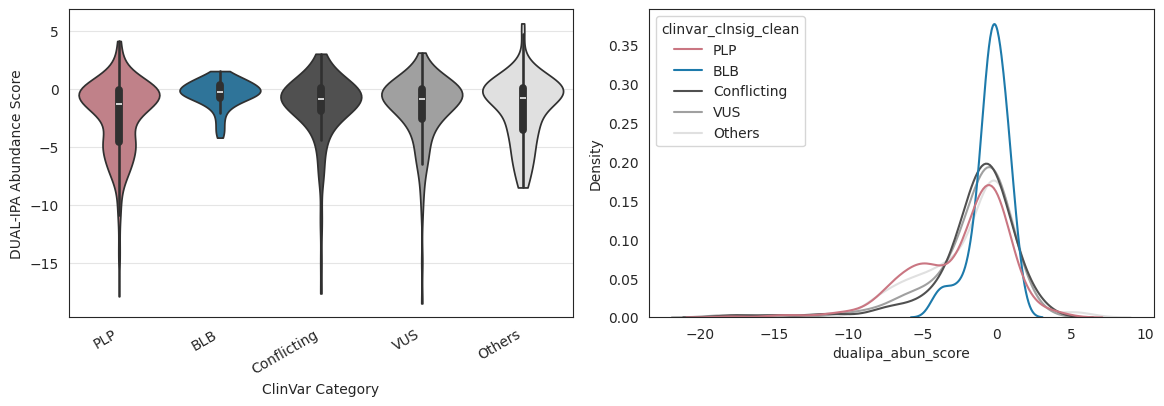

In [33]:
from seaborn.palettes import color_palette


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# sns.boxenplot(
#     data=scores.to_pandas(),
#     x="clinvar_clnsig_clean", 
#     y="dualipa_abun_score",
#     hue="clinvar_clnsig_clean", 
#     palette=palette_dict["clinvar_clnsig_clean"],
#     order=hue_order,
#     ax=axes[0]
# )
sns.violinplot(
    data=scores.to_pandas(),
    x="clinvar_clnsig_clean", 
    y="dualipa_abun_score",
    hue="clinvar_clnsig_clean", 
    palette=clinvar_palette_old,
    order=hue_order,
    cut=0,
    ax=axes[0]
)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right') ##
axes[0].set_xlabel("ClinVar Category") ##, rotation=45, ha='right'
axes[0].set_ylabel("DUAL-IPA Abundance Score") ##, rotation=45, ha='right'
axes[0].grid(alpha=0.5, axis="y")

sns.kdeplot(
    data=scores.to_pandas(),
    x="dualipa_abun_score",
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    ax=axes[1],
    palette=clinvar_palette_old,
    common_norm=False
)
plt.subplots_adjust(wspace=0.15)
plt.show()

#### 1.1.2 All ClinVar variants with somewhat clear annotations (other than "Others") & _ReviewStarStatus>=1_

In [34]:
# # Define variables to plot
# scores_filt = scores.filter(pl.col("StarStatus") >= 1)
# print("ClinVar Variants (StarStatus >= 1) Number:", scores_filt.shape[0])

# fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# sns.boxenplot(
#     data=scores_filt.to_pandas(),
#     x="clinvar_clnsig_clean", 
#     y="dualipa_abun_score",
#     hue="clinvar_clnsig_clean", 
#     palette=palette_dict["clinvar_clnsig_clean"],
#     order=hue_order,
#     ax=axes[0]
# )
# axes[0].grid(alpha=0.3, axis='y')

# sns.kdeplot(
#     data=scores_filt.to_pandas(),
#     x="dualipa_abun_score",
#     hue="clinvar_clnsig_clean",
#     hue_order=hue_order,
#     ax=axes[1],
#     palette=palette_dict["clinvar_clnsig_clean"],
#     common_norm=False
# )
# plt.subplots_adjust(wspace=0.15)
# plt.show()

### 1.2 All Inheritance_pattern

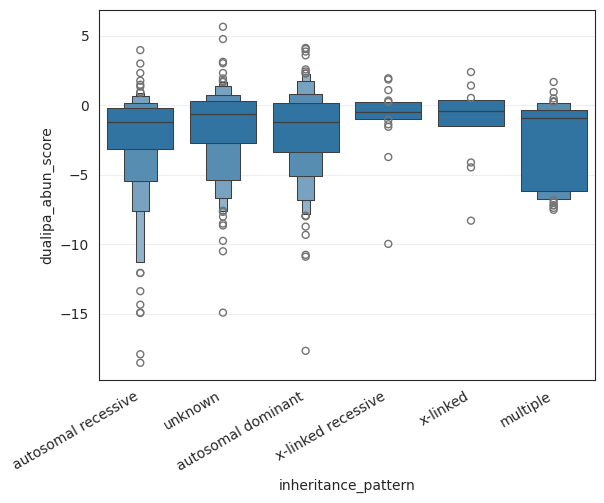

In [35]:
ax = sns.boxenplot(
    data=scores.to_pandas(),
    x="inheritance_pattern",
    y="dualipa_abun_score",
    # hue="inheritance_pattern",
    # hue_order=hue_order,
    #palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.show()

### 1.3 pLDDT + RSA

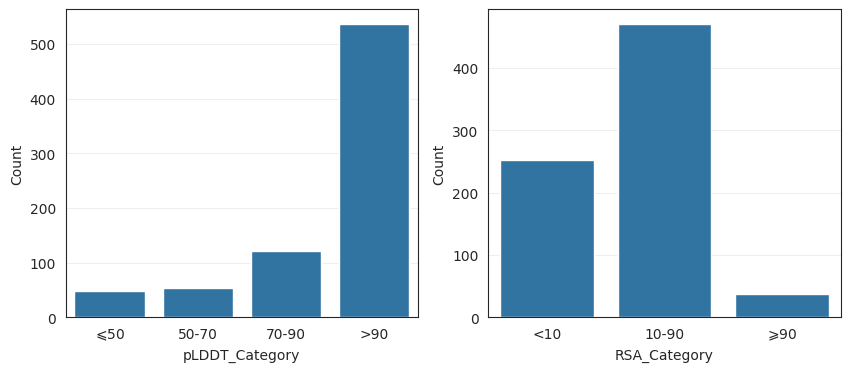

In [36]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.barplot(
    data=scores.group_by("pLDDT_Category").
    agg(
        pl.len().alias("Count")
    ).to_pandas(),
    x="pLDDT_Category", y="Count",
    ax=axes[0],
    order=["$\\leqslant$50", "50-70", "70-90", ">90"]
    # hue="pLDDT_Category", #palette=palette_dict["clinvar_clnsig_clean"]
)
sns.barplot(
    data=scores.group_by("RSA_Category").
    agg(
        pl.len().alias("Count")
    ).to_pandas(),
    x="RSA_Category", y="Count",
    ax=axes[1],
    order=["<10", "10-90", '$\\geqslant$90']
    # hue="pLDDT_Category", #palette=palette_dict["clinvar_clnsig_clean"]
)
axes[0].grid(alpha=0.3, axis='y')
axes[1].grid(alpha=0.3, axis='y')

# ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
plt.show()

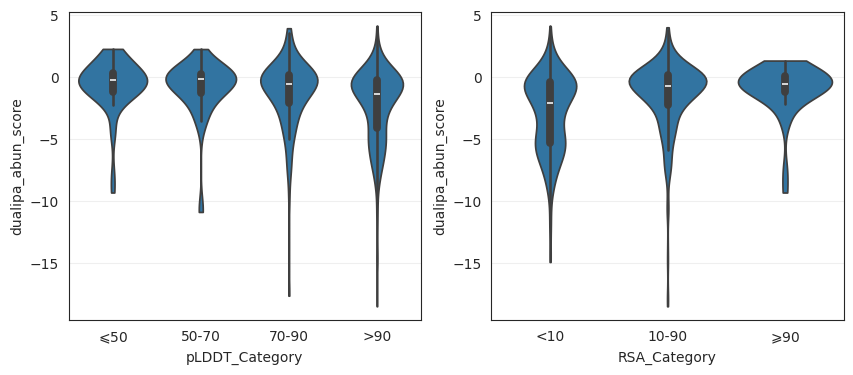

In [37]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.violinplot(
    data=scores.to_pandas(),
    x="pLDDT_Category", y="dualipa_abun_score",
    ax=axes[0],
    # hue="pLDDT_Category", #palette=palette_dict["clinvar_clnsig_clean"]
    order=["$\\leqslant$50", "50-70", "70-90", ">90"],
    cut=0
)
sns.violinplot(
    data=scores.to_pandas(),
    x="RSA_Category", y="dualipa_abun_score",
    ax=axes[1],
    order=["<10", "10-90", '$\\geqslant$90'],
    cut=0
    # hue="pLDDT_Category", #palette=palette_dict["clinvar_clnsig_clean"]
)
axes[0].grid(alpha=0.3, axis='y')
axes[1].grid(alpha=0.3, axis='y')
plt.show()

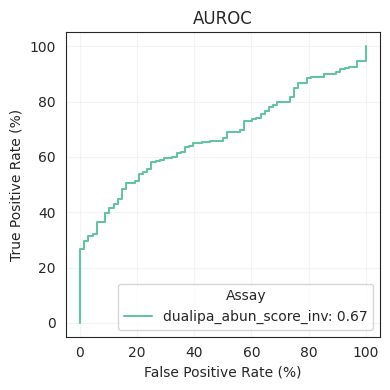

In [38]:
ap_results_dict = plot_auroc_curves(
    df_clinvar_w_scores=scores.with_columns(
        (-pl.col("dualipa_abun_score")).alias("dualipa_abun_score_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign", "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["dualipa_abun_score_inv"]
)

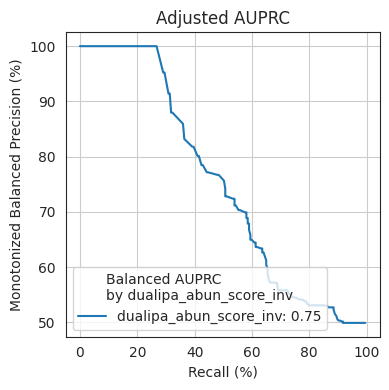

In [39]:
sys.path.insert(1, "../../../4_compare_ai_scores/2_analysis/scripts")
from yogiroc import *

def plot_adjusted_pr_curves(df_clinvar_w_scores, label, pos_labels, methods, monotonized_flag=True, balanced_flag=True, subsample=False, n_bootstrap=1000, random_state=None):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    assert (balanced_flag and not subsample) or (subsample and not balanced_flag) or (not subsample and not balanced_flag)
    
    ap_results_dict = {}
    # sig_results_dict = {}
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.with_columns(
            (
                pl.when(pl.col(label).is_in(pos_labels))
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=[label, met])
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        if subsample:
            # Assume df is your existing DataFrame with a column named "label"
            # Find the minimum count among the two classes (0 and 1)
            min_count = df_pd['clinvar_label'].value_counts().min()
            # Group by the 'label' column and sample min_count rows from each group (without replacement)
            df_pd = df_pd.groupby('clinvar_label').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)

        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]

        # Create the YogiROC2 object using the new YogiROC2() constructor.
        yrobj = YogiROC2(truth, scores, names=[met], high=True)
        # Get the performance table from the YogiROC2 object.
        table = yrobj.tables[met]

        if (monotonized_flag and balanced_flag):
            table = table.dropna()
        precision = configure_prec(table, monotonized_flag=monotonized_flag, balanced_flag=balanced_flag)
        recall = table["tpr_sens"].values
        # print(precision)
        # print(recall)
        ap = calc_auc(recall[~np.isnan(recall)], precision[~np.isnan(precision)])
        ap_results[met] = {"AUPRC": ap}

        # Plot the adjusted PR curve.
        axes[m_idx].plot(100 * recall, 100 * precision,
                        label=f"{met}: {ap:.2f}")
        # Plot chance level as a horizontal dashed line.
        prior = np.sum(truth) / df_pd.shape[0]
        if (not balanced_flag):
            axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
        # Customize the subplot.
        handles, labels = axes[methods.index(met)].get_legend_handles_labels()
        precision_label = "Precision (%)"
        title = f"AUPRC\nby {met}"
        
        if balanced_flag:
            precision_label = "Balanced " + precision_label
            title = "Balanced " + title
        if monotonized_flag:
            precision_label = "Monotonized " + precision_label
    
        axes[m_idx].legend(
                        loc="lower left",
                        title=title)
        axes[m_idx].set_xlabel("Recall (%)")
        axes[m_idx].set_ylabel(precision_label)
        axes[m_idx].set_title("Adjusted AUPRC")
        axes[m_idx].grid()

    # sig_results_dict[category] = significance

    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return None ## , sig_results_dict

plot_adjusted_pr_curves(df_clinvar_w_scores=scores.with_columns(
        (-pl.col("dualipa_abun_score")).alias("dualipa_abun_score_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign", "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["dualipa_abun_score_inv"]
)